<a href="https://colab.research.google.com/github/AnnMarie1312/seminarski-rac-vid/blob/main/XAI_Rendgenske_snimke_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Objašnjivost dubokih modela u klasifikaciji medicinskih slika
**Kolegij:** Računalni vid  
**Model:** ResNet18 (transfer learning)  
**Metode:** Grad-CAM, Grad-CAM++, Integrated Gradients  
**Zadatak:** Klasifikacija rendgenskih snimki pluća: NORMAL / PNEUMONIA

> Istraživački/obrazovni eksperiment, nije medicinski dijagnostički alat. Prvo uključite GPU: Runtime → Change runtime type → T4 GPU. Izvršavajte ćelije redom. Datoteke rezultata spremaju se u `/content/xai_rezultati`.

In [3]:
!pip -q install kagglehub grad-cam captum scikit-learn seaborn pandas pillow

## 1. Uvoz, konfiguracija i ponovljivost

In [4]:
import os, random, json, copy, shutil
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score, confusion_matrix, classification_report, roc_curve)
from tqdm.auto import tqdm
import kagglehub
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from captum.attr import IntegratedGradients
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT=Path('/content/xai_rezultati'); OUT.mkdir(parents=True, exist_ok=True)
BATCH_SIZE=32; EPOCHS=5; LR=1e-4; SIZE=224
print('Uređaj:',device)

Uređaj: cpu


## 2. Podaci i podjela
Javno dostupan skup **Chest X-Ray Images (Pneumonia)** (Kermany i sur.). KaggleHub preuzima javnu kopiju; ako preuzimanje ne uspije, ručno preuzmite skup i promijenite `DATA_ROOT`. Originalni testni skup ostaje netaknut. Iz originalnog trening skupa izdvajamo stratificirani validacijski podskup od 15 %. Izvorni `val` direktorij ne koristimo jer je premalen. **Ograničenje:** neovisnost na razini pacijenta nije provjerena, a snimke i oznake mogu sadržavati pristranosti.

In [5]:
dataset_path=Path(kagglehub.dataset_download('paultimothymooney/chest-xray-pneumonia'))
print('Preuzeto:',dataset_path)
candidates=[x for x in [dataset_path, *dataset_path.rglob('chest_xray')] if (x/'train'/'NORMAL').exists() and (x/'test'/'PNEUMONIA').exists()]
assert candidates, 'Nije pronađena očekivana struktura train/NORMAL i test/PNEUMONIA.'
DATA_ROOT=candidates[0]
CLASSES=['NORMAL','PNEUMONIA']; class_to_idx={c:i for i,c in enumerate(CLASSES)}
def files_for(split):
    return [(str(f),class_to_idx[c]) for c in CLASSES for f in sorted((DATA_ROOT/split/c).glob('*')) if f.suffix.lower() in ('.jpg','.jpeg','.png')]
train_all=files_for('train'); test_items=files_for('test')
train_items,val_items=train_test_split(train_all,test_size=0.15,random_state=SEED,stratify=[y for _,y in train_all])
for name,items in [('train',train_items),('val',val_items),('test',test_items)]:
 print(name,len(items),pd.Series([CLASSES[y] for _,y in items]).value_counts().to_dict())
assert len(train_items)>0 and len(test_items)>0

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Preuzeto: /kaggle/input/chest-xray-pneumonia
train 4433 {'PNEUMONIA': 3293, 'NORMAL': 1140}
val 783 {'PNEUMONIA': 582, 'NORMAL': 201}
test 624 {'PNEUMONIA': 390, 'NORMAL': 234}


## 3. Transformacije i DataLoader

In [6]:
MEAN=[0.485,0.456,0.406]; STD=[0.229,0.224,0.225]
train_tf=transforms.Compose([transforms.Resize((SIZE,SIZE)),transforms.RandomRotation(5),transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
eval_tf=transforms.Compose([transforms.Resize((SIZE,SIZE)),transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
class XrayDataset(Dataset):
 def __init__(self,items,transform): self.items=items;self.transform=transform
 def __len__(self): return len(self.items)
 def __getitem__(self,i):
  path,y=self.items[i]
  with Image.open(path) as im: im=im.convert('RGB'); x=self.transform(im)
  return x,y
loaders={name:DataLoader(XrayDataset(items,train_tf if name=='train' else eval_tf),batch_size=BATCH_SIZE,shuffle=name=='train',num_workers=2,pin_memory=torch.cuda.is_available()) for name,items in [('train',train_items),('val',val_items),('test',test_items)]}

## 4. ResNet18 – transfer learning i treniranje

In [ ]:
weights=models.ResNet18_Weights.DEFAULT
model=models.resnet18(weights=weights)
model.fc=nn.Linear(model.fc.in_features,2)
model=model.to(device)
counts=np.bincount([y for _,y in train_items],minlength=2)
class_weights=torch.tensor(len(train_items)/(2*counts),dtype=torch.float32,device=device)
criterion=nn.CrossEntropyLoss(weight=class_weights)
optimizer=torch.optim.Adam(model.parameters(),lr=LR)
history=[]; best_val=float('inf'); best_state=None
for epoch in range(EPOCHS):
 row={'epoch':epoch+1}
 for phase in ('train','val'):
  model.train(phase=='train'); losses=[]; correct=total=0
  for x,y in tqdm(loaders[phase],desc=f'Epoha {epoch+1}/{EPOCHS} {phase}',leave=False):
   x=x.to(device);y=y.to(device)
   optimizer.zero_grad(set_to_none=True)
   with torch.set_grad_enabled(phase=='train'):
    logits=model(x); loss=criterion(logits,y)
    if phase=='train':loss.backward();optimizer.step()
   losses.append(loss.item()*len(y));correct+=(logits.argmax(1)==y).sum().item();total+=len(y)
  row[f'{phase}_loss']=sum(losses)/total;row[f'{phase}_accuracy']=correct/total
 history.append(row);print(row)
 if row['val_loss']<best_val:
  best_val=row['val_loss'];best_state=copy.deepcopy(model.state_dict())
model.load_state_dict(best_state);model.eval()
torch.save({'state_dict':best_state,'classes':CLASSES,'size':SIZE},OUT/'resnet18_best.pt')
pd.DataFrame(history).to_csv(OUT/'povijest_treniranja.csv',index=False)
pd.DataFrame(history).plot(x='epoch',y=['train_loss','val_loss'],marker='o');plt.tight_layout();plt.savefig(OUT/'krivulje_gubitka.png',dpi=160);plt.show()

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 136MB/s]


Epoha 1/5 train:   0%|          | 0/139 [00:00<?, ?it/s]

Epoha 1/5 val:   0%|          | 0/25 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f384460f740>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7f384460f740>if w.is_alive():

Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
assert self._parent_pid == os.getpid(), 'can only test a child process'
    AssertionErrorself._shutdown_workers(): can only test a child process
Exception ignored in: 
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
<function _Multi

{'epoch': 1, 'train_loss': 0.11318255655052376, 'train_accuracy': 0.9587187006541845, 'val_loss': 0.05819089439701132, 'val_accuracy': 0.9731800766283525}


Epoha 2/5 train:   0%|          | 0/139 [00:00<?, ?it/s]

## 5. Evaluacija na izdvojenom testnom skupu

In [9]:
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Uređaj spreman:", device)

Uređaj spreman: cpu


In [12]:
import os, random, copy
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
import kagglehub

# Ponovno postavljanje parametara
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT = Path('/content/xai_rezultati'); OUT.mkdir(parents=True, exist_ok=True)
BATCH_SIZE = 32; SIZE = 224; CLASSES = ['NORMAL', 'PNEUMONIA']
class_to_idx = {c: i for i, c in enumerate(CLASSES)}

# 1. Preuzimanje podataka
dataset_path = Path(kagglehub.dataset_download('paultimothymooney/chest-xray-pneumonia'))
candidates = [x for x in [dataset_path, *dataset_path.rglob('chest_xray')] if (x/'train'/'NORMAL').exists() and (x/'test'/'PNEUMONIA').exists()]
DATA_ROOT = candidates[0]

def files_for(split):
    return [(str(f), class_to_idx[c]) for c in CLASSES for f in sorted((DATA_ROOT/split/c).glob('*')) if f.suffix.lower() in ('.jpg', '.jpeg', '.png')]

train_all = files_for('train'); test_items = files_for('test')
train_items, val_items = train_test_split(train_all, test_size=0.15, random_state=SEED, stratify=[y for _, y in train_all])

# 2. Priprema Loadera
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
eval_tf = transforms.Compose([transforms.Resize((SIZE, SIZE)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class XrayDataset(Dataset):
    def __init__(self, items, transform):
        self.items = items
        self.transform = transform
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        path, y = self.items[i]
        with Image.open(path) as im:
            im = im.convert('RGB')
            x = self.transform(im)
        return x, y

loaders = {
    'test': DataLoader(XrayDataset(test_items, eval_tf), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())
}

# 3. Učitavanje modela
model = models.resnet18()
model.fc = nn.Linear(model.fc.in_features, 2)
checkpoint_path = OUT/'resnet18_best.pt'
if checkpoint_path.exists():
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint['state_dict'])
    print("Uspješno učitan spremljeni model s diska.")
else:
    print("Spremljeni model nije pronađen na disku. Ako ste tek pokrenuli sesiju, pokrenite ćeliju pod brojem 4 za treniranje modela.")
model = model.to(device)
model.eval()

print("Sve varijable i 'loaders' su uspješno inicijalizirani!")

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Spremljeni model nije pronađen na disku. Ako ste tek pokrenuli sesiju, pokrenite ćeliju pod brojem 4 za treniranje modela.
Sve varijable i 'loaders' su uspješno inicijalizirani!


accuracy               0.6250
precision_pneumonia    0.6250
recall_pneumonia       1.0000
f1_pneumonia           0.7692
auroc                  0.2508
dtype: float64
              precision    recall  f1-score   support

      NORMAL       0.00      0.00      0.00       234
   PNEUMONIA       0.62      1.00      0.77       390

    accuracy                           0.62       624
   macro avg       0.31      0.50      0.38       624
weighted avg       0.39      0.62      0.48       624



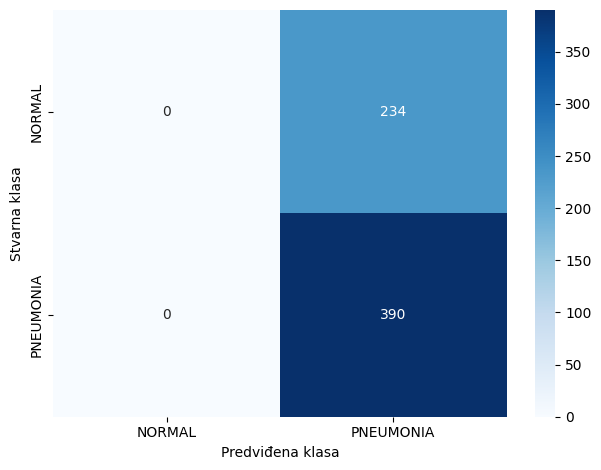

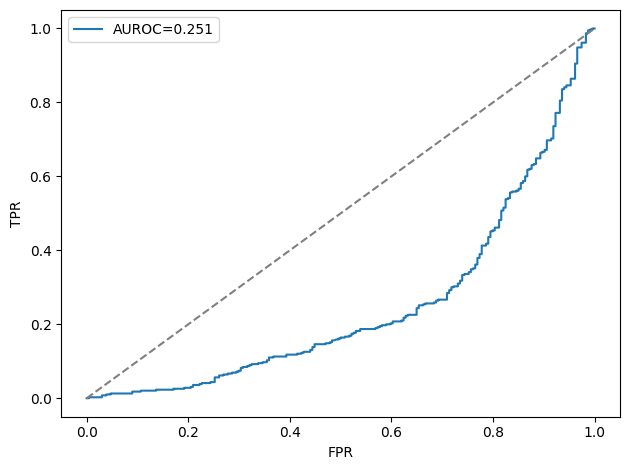

In [13]:
import torch
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score, confusion_matrix, classification_report, roc_curve

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ys = []
preds = []
probs = []

with torch.no_grad():
    for x, y in loaders['test']:
        logits = model(x.to(device))
        p = logits.softmax(1)[:, 1].cpu().numpy()
        ys.extend(y.numpy().tolist())
        probs.extend(p.tolist())
        preds.extend((p >= 0.5).astype(int).tolist())

ys = np.array(ys)
preds = np.array(preds)
probs = np.array(probs)

pr, rc, f1, _ = precision_recall_fscore_support(ys, preds, average='binary', zero_division=0)
metrics = {
    'accuracy': accuracy_score(ys, preds),
    'precision_pneumonia': pr,
    'recall_pneumonia': rc,
    'f1_pneumonia': f1,
    'auroc': roc_auc_score(ys, probs)
}

print(pd.Series(metrics).round(4))
print(classification_report(ys, preds, target_names=CLASSES, zero_division=0))
pd.DataFrame([metrics]).to_csv(OUT/'metrike.csv', index=False)

cm = confusion_matrix(ys, preds, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', xticklabels=CLASSES, yticklabels=CLASSES, cmap='Blues')
plt.xlabel('Predviđena klasa')
plt.ylabel('Stvarna klasa')
plt.tight_layout()
plt.savefig(OUT/'matrica_zabune.png', dpi=170)
plt.show()

fpr, tpr, _ = roc_curve(ys, probs)
plt.plot(fpr, tpr, label=f'AUROC={metrics["auroc"]:.3f}')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()
plt.tight_layout()
plt.savefig(OUT/'roc.png', dpi=170)
plt.show()

pd.DataFrame({'path': [x for x, _ in test_items], 'true': ys, 'pred': preds, 'p_pneumonia': probs}).to_csv(OUT/'test_predikcije.csv', index=False)

In [9]:
for var_name in ['loaders', 'model', 'CLASSES']:
    is_defined = var_name in globals() or var_name in locals()
    print(f"Varijabla '{var_name}': {'DEFINIRANA' if is_defined else 'NIJE DEFINIRANA'}")

Varijabla 'loaders': NIJE DEFINIRANA
Varijabla 'model': NIJE DEFINIRANA
Varijabla 'CLASSES': NIJE DEFINIRANA


## 6. XAI: Grad-CAM, Grad-CAM++ i Integrated Gradients
Sve metode objašnjavaju **predviđenu klasu** na istom ulazu. Za Grad-CAM metode koristi se posljednji konvolucijski blok (`layer4[-1]`). Za Integrated Gradients početna referenca je crna slika u nenormaliziranom RGB prostoru, zatim normalizirana istom transformacijom. Vizualizacije su **relativne atribucije**, ne dokazi patološke lokalizacije.

In [8]:
import sys
import subprocess

# Provjera i automatska instalacija potrebnih biblioteka ako nedostaju
try:
    import pytorch_grad_cam
    from captum.attr import IntegratedGradients
except ImportError:
    print("Instalacija potrebnih paketa (grad-cam, captum)...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "grad-cam", "captum"])
    print("Paketi su uspješno instalirani!")

from pytorch_grad_cam import GradCAM, GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from captum.attr import IntegratedGradients
from matplotlib import colors

# Osigurajmo da su ys i preds generirani u slučaju da ćelija 5 nije pokrenuta
if 'ys' not in globals() or 'preds' not in globals():
    print("Generiranje predviđanja (ys i preds) u tijeku...")
    ys_list = []
    preds_list = []
    model.eval()
    with torch.no_grad():
        for x, y in loaders['test']:
            logits = model(x.to(device))
            p = logits.softmax(1)[:, 1].cpu().numpy()
            ys_list.extend(y.numpy().tolist())
            preds_list.extend((p >= 0.5).astype(int).tolist())
    ys = np.array(ys_list)
    preds = np.array(preds_list)

def explain_one(index,save=True):
 path,true=test_items[index]
 with Image.open(path) as im: raw=np.asarray(im.convert('RGB').resize((SIZE,SIZE)),dtype=np.float32)/255.0
 x=eval_tf(Image.fromarray((raw*255).astype('uint8'))).unsqueeze(0).to(device)
 model.eval()
 with torch.no_grad(): predicted=int(model(x).argmax(1).item());confidence=float(model(x).softmax(1)[0,predicted].item())
 targets=[ClassifierOutputTarget(predicted)]
 with GradCAM(model=model,target_layers=[model.layer4[-1]]) as cam:
  gc=cam(input_tensor=x,targets=targets)[0]
 with GradCAMPlusPlus(model=model,target_layers=[model.layer4[-1]]) as cam:
  gcpp=cam(input_tensor=x,targets=targets)[0]
 baseline=transforms.Normalize(MEAN,STD)(torch.zeros_like(x[0]).cpu()).unsqueeze(0).to(device)
 ig=IntegratedGradients(model)
 attr=ig.attribute(x,baselines=baseline,target=predicted,n_steps=32,internal_batch_size=8)
 # apsolutna atribucija, agregirana po kanalima
 heat=attr.detach().abs().sum(dim=1)[0].cpu().numpy()
 heat=(heat-heat.min())/(np.ptp(heat)+1e-8)
 fig,ax=plt.subplots(1,4,figsize=(16,4))
 ax[0].imshow(raw);ax[0].set_title('Izvorna slika')
 ax[1].imshow(show_cam_on_image(raw,gc,use_rgb=True));ax[1].set_title('Grad-CAM')
 ax[2].imshow(show_cam_on_image(raw,gcpp,use_rgb=True));ax[2].set_title('Grad-CAM++')
 ax[3].imshow(raw);ax[3].imshow(heat,cmap='jet',alpha=0.45,vmin=0,vmax=1);ax[3].set_title('Integrated Gradients')
 for a in ax:a.axis('off')
 fig.suptitle(f'Stvarno: {CLASSES[true]} | Predviđeno: {CLASSES[predicted]} | p={confidence:.3f}')
 plt.tight_layout()
 if save:fig.savefig(OUT/f'xai_test_{index}.png',dpi=180,bbox_inches='tight')
 plt.show();plt.close(fig)
 return {'index':index,'path':path,'true':CLASSES[true],'predicted':CLASSES[predicted],'confidence':confidence}

# Prikaz dva točna i dva pogrešna primjera, ako postoje
correct=np.flatnonzero(ys==preds);wrong=np.flatnonzero(ys!=preds)
selected=list(correct[:2])+list(wrong[:2]);print('Odabrani indeksi:',selected)
examples=[explain_one(int(i)) for i in selected]
pd.DataFrame(examples).to_csv(OUT/'xai_primjeri.csv',index=False)

Generiranje predviđanja (ys i preds) u tijeku...


NameError: name 'model' is not defined

## 7. Analiza i izvoz
Za svaku mapu provjerite: (1) jesu li istaknuta plućna polja ili rubovi/oznake, (2) jesu li tri metode suglasne, (3) postoje li lažno pozitivni i lažno negativni primjeri. Bez anotacija radiologa nije moguće objektivno potvrditi kliničku lokalizaciju. Unesite **vlastita opažanja** u Word rad. ZIP preuzmite iz Colaba.

In [ ]:
summary={'dataset':'Chest X-Ray Images (Pneumonia), Kaggle paultimothymooney','model':'ResNet18','seed':SEED,'epochs':EPOCHS,'split':{'train':len(train_items),'val':len(val_items),'test':len(test_items)},'metrics':metrics,'limitations':['Nije potvrđena neovisnost pacijenata','Nema radioloških anotacija za lokalizacijsku validaciju','Jedan skup podataka; nije provjerena vanjska generalizacija']}
(OUT/'sazetak.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
shutil.make_archive('/content/xai_rezultati','zip',OUT)
from google.colab import files
files.download('/content/xai_rezultati.zip')